In [1]:
%pip install yfinance

  Using cached beautifulsoup4-4.15.0-py3-none-any.whl.metadata (3.8 kB)
Using cached beautifulsoup4-4.15.0-py3-none-any.whl (109 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 2.1 MB/s  0:00:06 eta 0:00:010:01:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 4.6 MB/s  0:00:01m 4.6 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 5.5 MB/s  0:00:025.6 MB/s eta 0:00:0101
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [yfinance] 10/11 [yfinance]rl_cffi]]

[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance  as yf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout

np.random.seed(42)
import tensorflow as tf
tf.random.set_seed(42)

In [9]:
ticker = 'AAPL'
df = yf.download(ticker, start='2018-01-01', end='2023-12-31')

[*********************100%***********************]  1 of 1 completed


In [12]:
if 'Adj Close' in df.columns:
    data = df[['Adj close']]
elif ('Adj Close', ticker) in df.columns:
    data = df[['Adj Close', ticker]]
else:
    data = df[['Close']]

In [13]:
data.columns = ['close']
display(data.head())

,close
Date,
2018-01-02,40.232380
2018-01-03,40.225368
2018-01-04,40.412224
2018-01-05,40.872314
2018-01-08,40.720520


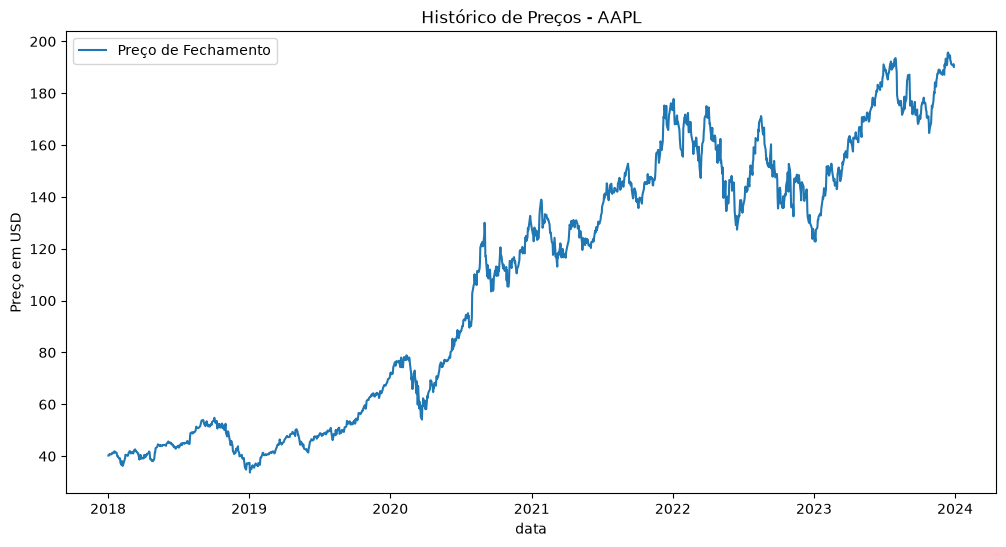

In [16]:
plt.figure(figsize=(12, 6))
plt.plot(data, label='Preço de Fechamento')
plt.title("Histórico de Preços - AAPL")
plt.xlabel("data")
plt.ylabel('Preço em USD')
plt.legend()
plt.show()

In [38]:
dataset = data.values
training_data_len = int(np.ceil(len(dataset)*0.8))

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data =scaler.fit_transform(dataset)

train_data = scaled_data[0:int(training_data_len), :]

X_train = []
y_train = []

for i in range (60, len(train_data)):
        X_train.append(train_data[i-60:i, 0])
        y_train.append(train_data[i, 0])
X_train, y_train = np.array(X_train), np.array(y_train)
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))

In [39]:
model = Sequential()
model.add(LSTM(units=50, return_sequences=True, input_shape=(X_train.shape[1], 1)))
model.add(Dropout(0.2))
model.add(LSTM(units=50, return_sequences=False))
model.add(Dropout(0.2))
model.add(Dense(units=1))
model.compile(optimizer='adam', loss='mean_squared_error')
model.fit(X_train, y_train, batch_size=32, epochs=15, validation_split=0.1)

E0000 00:00:1794248361.550163    3630 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50

/home/marcos/repos/lstm/venv/lib/python3.14/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 5s 96ms/step - loss: 0.0239 - val_loss: 0.0051
Epoch 2/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0038 - val_loss: 0.0028
Epoch 3/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.0030 - val_loss: 0.0042
Epoch 4/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.0029 - val_loss: 0.0022
Epoch 5/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - loss: 0.0028 - val_loss: 0.0030
Epoch 6/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - loss: 0.0024 - val_loss: 0.0028
Epoch 7/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - loss: 0.0024 - val_loss: 0.0019
Epoch 8/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - loss: 0.0024 - val_loss: 0.0037
Epoch 9/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0022 - val_loss: 0.0020
Epoch 10/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0024 - val_loss: 0.0018
Epoch 11/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - loss: 0.0019 - val_loss: 0.0024
Epoch 12/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0

In [40]:
test_data = scaled_data[training_data_len - 60:, :]
X_test = []
y_test = dataset[training_data_len:, :]
for i in range(60, len(test_data)):
    X_test.append(test_data[i-60:i, 0])
X_test = np.array(X_test)
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

predictions = model.predict(X_test)
predictions = scaler.inverse_transform(predictions)

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step


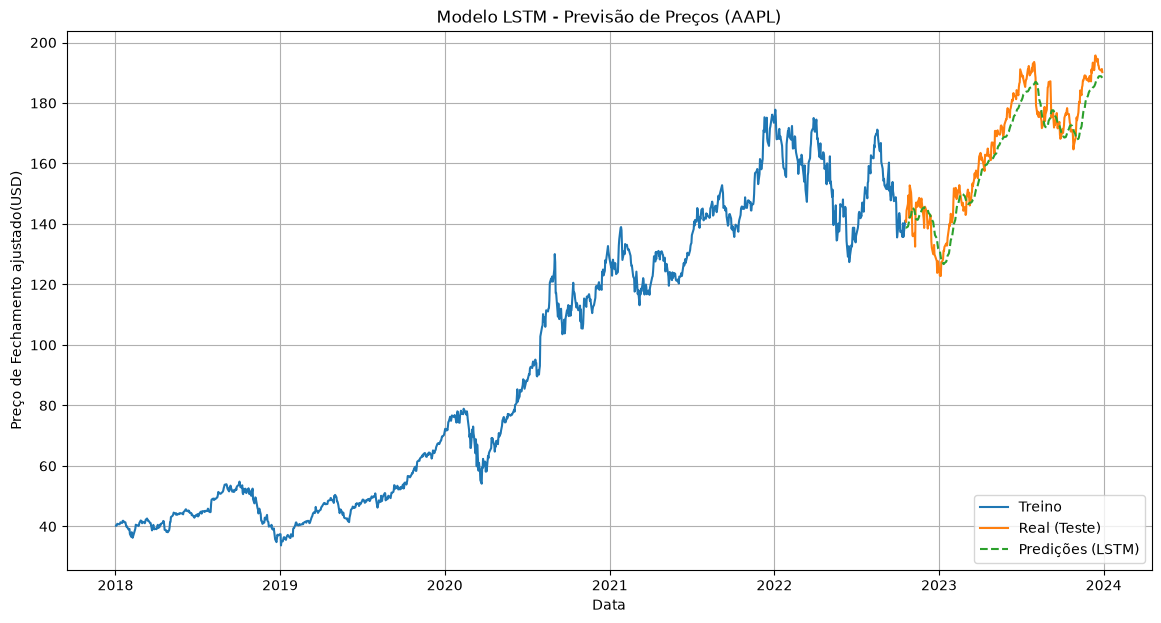

In [48]:
train = data[:training_data_len]
valid = data[training_data_len:]
valid['Predictions'] = predictions

plt.figure(figsize=(14, 7))
plt.title('Modelo LSTM - Previsão de Preços (AAPL)')
plt.xlabel('Data')
plt.ylabel('Preço de Fechamento ajustado(USD)')
plt.plot(train['close'], label='Treino')
plt.plot(valid['close'], label='Real (Teste)')
plt.plot(valid['Predictions'], label='Predições (LSTM)', linestyle='--')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()